# Interconnect · 03b — Exploración individual de `personal.csv`

**Proyecto:** Predicción de abandono de clientes · TripleTen  
**Etapa:** Comprensión y auditoría individual de fuentes (CRISP-DM)  
**Alcance:** describir características personales registradas, validar calidad y explorar asociaciones **entre variables de esta tabla**. **No unir**, no calcular Churn ni entrenar modelos en este notebook.

> **Estado:** investigación por ejecutar con los CSV locales. Las conclusiones finales se redactarán después de revisar los resultados reales.

### Preguntas de investigación
1. ¿Cada registro corresponde a un cliente distinto? ¿Hay valores ausentes, espacios o categorías inconsistentes?
2. ¿Cómo se distribuyen `gender`, `SeniorCitizen`, `Partner` y `Dependents`?
3. ¿Existe asociación descriptiva entre `Partner` y `Dependents`?

**Nota de interpretación:** son atributos registrados, no evidencia de motivaciones, satisfacción, preferencias o causas de abandono.

## A. Lectura de datos y criterios de presentación

Leemos `data/raw/personal.csv` en modo de **solo lectura**. El objetivo es auditar el origen antes de dar por validada la copia `personal_clean.csv`. No se modifican ni sobrescriben archivos.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Configuración visual: misma familia cromática de la investigación de contratos.
COLOR = {
    "tinta": "#263746",
    "muted": "#61737F",
    "grid": "#DCE5EA",
    "si": "#23877F",
    "no": "#9DAEB8",
    "contraste": "#D16E46",
    "referencia": "#547B91",
}
plt.rcParams.update({
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 12,
    "axes.titleweight": "semibold",
    "axes.labelsize": 10,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": COLOR["tinta"],
    "axes.labelcolor": COLOR["tinta"],
    "axes.titlecolor": COLOR["tinta"],
    "xtick.color": COLOR["muted"],
    "ytick.color": COLOR["muted"],
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
})

# Funciona tanto desde la raíz como desde notebooks/ en VS Code.
ruta_personal = next(
    (carpeta / "data" / "raw" / "personal.csv"
     for carpeta in [Path.cwd(), *Path.cwd().parents]
     if (carpeta / "data" / "raw" / "personal.csv").is_file()),
    None
)
if ruta_personal is None:
    raise FileNotFoundError(
        f"No se encontró data/raw/personal.csv desde {Path.cwd()} ni en sus carpetas superiores."
    )

personal = pd.read_csv(ruta_personal, dtype={"customerID": "string"})
print("Archivo:", ruta_personal)
print("Dimensiones:", personal.shape)
print("Columnas:", personal.columns.tolist())
print("\nInformación estructural:")
personal.info()
display(personal.head())

Archivo: e:\data tree\data science\tripleten bootcamp\sprint 19 proyecto final\interconnect-churn-prediction\data\raw\personal.csv
Dimensiones: (7043, 5)
Columnas: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents']

Información estructural:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   string
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(3), string(1)
memory usage: 275.2+ KB


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


## B. Auditoría estructural y de calidad

**Pregunta:** ¿la tabla tiene una fila por cliente y categorías válidas? Evaluamos duplicados, nulos y espacios, incluidos aquellos que Pandas no considera `NaN`.

**Criterio:** no corregir ni eliminar registros automáticamente. Primero documentar las anomalías.

In [2]:
columnas_esperadas = ["customerID", "gender", "SeniorCitizen", "Partner", "Dependents"]
faltantes = sorted(set(columnas_esperadas) - set(personal.columns))
if faltantes:
    raise ValueError(f"Faltan columnas esperadas en personal.csv: {faltantes}")

print("Registros:", len(personal))
print("Clientes únicos:", personal["customerID"].nunique(dropna=True))
print("IDs duplicados:", personal["customerID"].duplicated().sum())
print("Filas duplicadas:", personal.duplicated().sum())
print("\nValores nulos reconocidos por Pandas:")
display(personal.isna().sum().rename("nulos"))

columnas_texto = personal.select_dtypes(include=["object", "string"]).columns
vacios_texto = personal[columnas_texto].apply(
    lambda columna: columna.astype("string").str.strip().eq("").sum()
)
print("\nCadenas vacías o con solo espacios:")
display(vacios_texto.rename("vacios_texto"))

print("\nValores originales distintos por columna:")
for columna in columnas_esperadas[1:]:
    print(f"\n{columna}:")
    display(personal[columna].value_counts(dropna=False).rename_axis("valor").to_frame("clientes"))

Registros: 7043
Clientes únicos: 7043
IDs duplicados: 0
Filas duplicadas: 0

Valores nulos reconocidos por Pandas:


customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
Name: nulos, dtype: int64


Cadenas vacías o con solo espacios:


customerID    0
gender        0
Partner       0
Dependents    0
Name: vacios_texto, dtype: int64


Valores originales distintos por columna:

gender:


...

,clientes
valor,
0,5901
1,1142



Partner:


,clientes
valor,
No,3641
Yes,3402



Dependents:


,clientes
valor,
No,4933
Yes,2110


### B1. Normalización de inspección (sin alterar el original)

Generamos una **copia temporal** en minúsculas para verificar categorías con independencia de mayúsculas o espacios. `SeniorCitizen` debe tratarse como un indicador `0/1`, **no como edad numérica**. No se interpreta que `SeniorCitizen=1` indique una edad exacta.

In [3]:
personal_vista = personal.copy()
for columna in ["gender", "Partner", "Dependents"]:
    personal_vista[columna] = (
        personal_vista[columna]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.casefold()
        .replace("", pd.NA)
    )

personal_vista["SeniorCitizen"] = pd.to_numeric(
    personal_vista["SeniorCitizen"], errors="coerce"
).astype("Int64")

permitidos = {
    "gender": {"female", "male"},
    "SeniorCitizen": {0, 1},
    "Partner": {"yes", "no"},
    "Dependents": {"yes", "no"},
}

revision = []
for columna, esperados in permitidos.items():
    presentes = set(personal_vista[columna].dropna().unique().tolist())
    inesperados = sorted(presentes - esperados)
    revision.append({
        "variable": columna,
        "categorias_detectadas": ", ".join(map(str, sorted(presentes))),
        "valores_fuera_de_catalogo": ", ".join(map(str, inesperados)) or "ninguno",
        "faltantes_tras_normalizar": int(personal_vista[columna].isna().sum()),
    })

display(pd.DataFrame(revision))
print("Nota: personal (origen) permanece sin cambios.")

,variable,categorias_detectadas,valores_fuera_de_catalogo,faltantes_tras_normalizar
0,gender,"female, male",ninguno,0
1,SeniorCitizen,"0, 1",ninguno,0
2,Partner,"no, yes",ninguno,0
3,Dependents,"no, yes",ninguno,0


Nota: personal (origen) permanece sin cambios.


## C. Distribución de características personales

**Pregunta:** ¿cuál es la composición observada de la población registrada en `personal.csv`? La referencia de cada porcentaje es el **total de registros** de esta tabla, incluso si hubiera valores faltantes.

Los porcentajes muestran distribución, no asociación con Churn. Conservamos la terminología original de las variables.

In [4]:
nombres_categoria = {
    "gender": {"female": "Female", "male": "Male"},
    "SeniorCitizen": {0: "No (0)", 1: "Sí (1)"},
    "Partner": {"no": "No", "yes": "Yes"},
    "Dependents": {"no": "No", "yes": "Yes"},
}

resumen_personal = []
for variable in permitidos:
    conteos = personal_vista[variable].value_counts(dropna=False)
    for valor, cantidad in conteos.items():
        etiqueta = ("Faltante" if pd.isna(valor)
                    else nombres_categoria[variable].get(valor, str(valor)))
        resumen_personal.append({
            "variable": variable,
            "categoria": etiqueta,
            "clientes": int(cantidad),
            "porcentaje_total": round(100 * cantidad / len(personal_vista), 2),
        })

frecuencias_personal = pd.DataFrame(resumen_personal)
display(frecuencias_personal)

,variable,categoria,clientes,porcentaje_total
0,gender,Male,3555,50.48
1,gender,Female,3488,49.52
2,SeniorCitizen,No (0),5901,83.79
3,SeniorCitizen,Sí (1),1142,16.21
4,Partner,No,3641,51.70
5,Partner,Yes,3402,48.30
6,Dependents,No,4933,70.04
7,Dependents,Yes,2110,29.96


### C1. Gráficas de distribución

Cuatro paneles con escala común (0–100 %), porcentajes etiquetados y paleta consistente. No hay eje de riesgo ni valores de Churn: son **frecuencias de la población**.

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


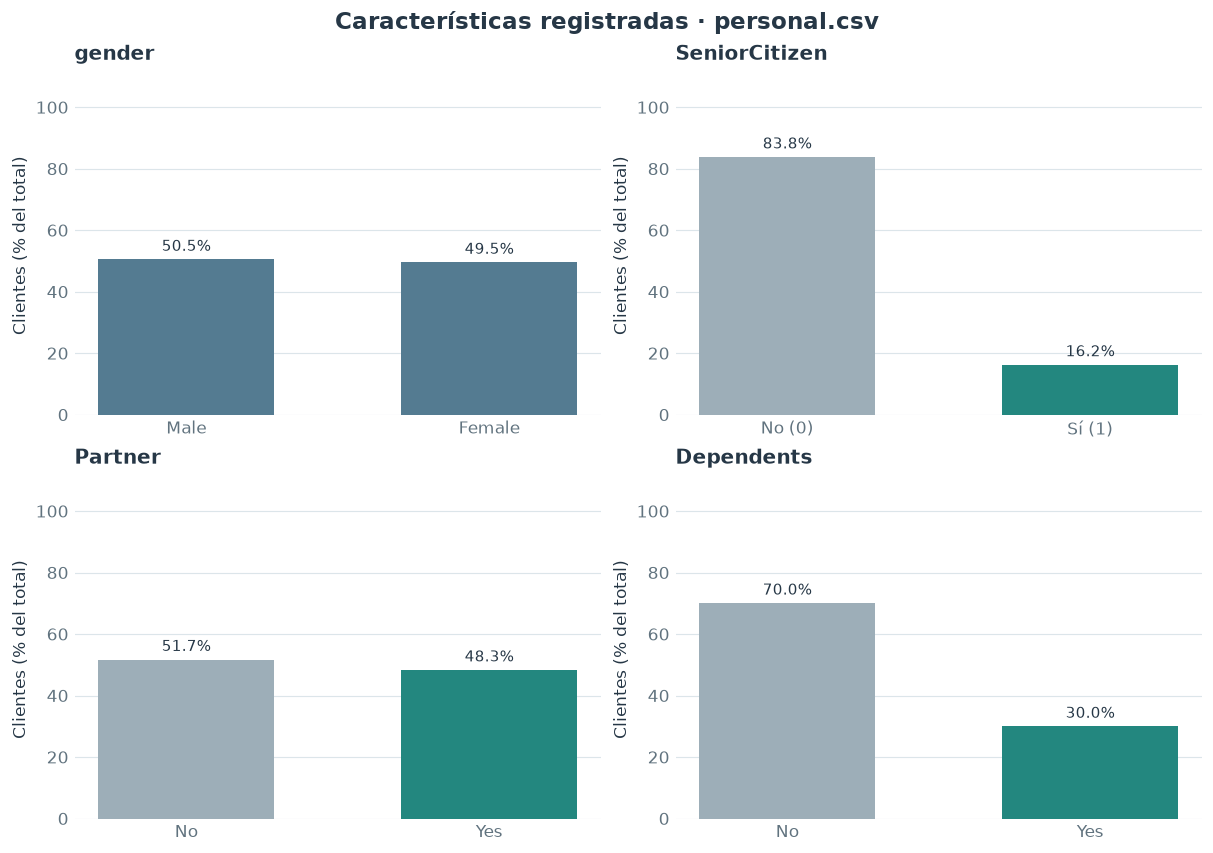

In [5]:
fig, ejes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")

for ax, variable in zip(ejes.flat, permitidos):
    datos = frecuencias_personal.loc[frecuencias_personal["variable"] == variable]
    etiquetas = datos["categoria"].tolist()
    valores = datos["porcentaje_total"].tolist()
    colores = [COLOR["si"] if et in {"Yes", "Sí (1)"} else COLOR["referencia"]
               if et in {"Female", "Male"} else COLOR["no"] for et in etiquetas]
    barras = ax.bar(etiquetas, valores, color=colores, width=0.58)
    ax.bar_label(barras, labels=[f"{v:.1f}%" for v in valores], padding=3, fontsize=9)
    ax.set_title(variable, loc="left", pad=10)
    ax.set_ylim(0, 110)
    ax.set_ylabel("Clientes (% del total)")
    ax.grid(axis="y", color=COLOR["grid"], linewidth=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

fig.suptitle("Características registradas · personal.csv", fontsize=14,
             fontweight="semibold", color=COLOR["tinta"])
plt.show()

## D. Relación descriptiva entre `Partner` y `Dependents`

**Pregunta:** ¿se registran dependientes con distinta frecuencia según la categoría de `Partner`? Esta comparación no implica vínculos familiares concretos ni relaciones de causa-efecto.

Los porcentajes se calculan **dentro de cada categoría de Partner** y se muestran junto con los conteos para detectar grupos pequeños.

In [6]:
conteos_pareja = pd.crosstab(
    personal_vista["Partner"], personal_vista["Dependents"], dropna=False
)
porcentajes_pareja = pd.crosstab(
    personal_vista["Partner"], personal_vista["Dependents"],
    normalize="index", dropna=False
).mul(100).round(1)

print("Clientes por combinación:")
display(conteos_pareja)
print("Porcentaje dentro de cada categoría de Partner:")
display(porcentajes_pareja)

Clientes por combinación:


Dependents,no,yes
Partner,,
no,3280,361
yes,1653,1749


Porcentaje dentro de cada categoría de Partner:


Dependents,no,yes
Partner,,
no,90.1,9.9
yes,48.6,51.4


## E. Conclusiones y decisiones para la integración

**Completar después de ejecutar las celdas con los datos reales:**

| Bloque | Evidencia por registrar | Decisión |
|---|---|---|
| A — Estructura | Filas, columnas y variables observadas | Confirmar granularidad por `customerID` |
| B — Calidad | Nulos, duplicados, espacios, categorías no previstas | Justificar normalizaciones necesarias |
| C — Composición | Porcentajes de `gender`, `SeniorCitizen`, `Partner`, `Dependents` | Conservar variables originales sin inferir motivaciones |
| D — Relación | Conteos y proporciones `Partner` × `Dependents` | Determinar si hay alguna asociación descriptiva relevante |

**Reglas para el siguiente notebook de integración**

- Preservar los cuatro CSV de `data/raw/`.
- Usar `customerID` para verificar correspondencias; una fila por cliente en la tabla maestra.
- `SeniorCitizen` es un indicador binario, no una variable de edad continua.
- Los atributos de `personal` se describen aquí **sin conocer Churn**; su asociación con el abandono se evaluará después, comparando activos y desertores con denominadores adecuados.
- Si existe `data/processed/personal_clean.csv`, revisarlo contra las categorías auditadas antes de tratarlo como versión validada.
- No introducir imputación ni codificación para Machine Learning en esta fase.

**Estado del notebook:** auditoría y exploración preparadas. Pendiente completar conclusiones con los resultados obtenidos localmente.